In [2]:
import os
import pickle
import numpy as np
import pandas as pd

In [ ]:
import neurokit2 as nk

# Set paths
wesad_dir = r"E:\AVIA\data\raw\WESAD\WESAD"
output_csv = r"E:\AVIA\data\processed\wesad\wesad_features_master.csv"

# WESAD subjects (S1 and S12 were discarded due to sensor malfunction)
subject_ids = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 14, 15, 16, 17]

window_size_sec = 60
step_size_sec = 10
fs_chest = 700  # RespiBAN sampling rate (700 Hz)

window_len = window_size_sec * fs_chest
step_len = step_size_sec * fs_chest

all_features = []

print("Starting WESAD Feature Extraction across subjects...")

for sid in subject_ids:
    subj_code = f"S{sid}"
    pkl_path = os.path.join(wesad_dir, subj_code, f"{subj_code}.pkl")
    
    if not os.path.exists(pkl_path):
        print(f"[Skipping] {pkl_path} not found.")
        continue
        
    print(f"\n[Processing] {subj_code}...")
    
    # Load synchronized dictionary
    with open(pkl_path, 'rb') as f:
        data = pickle.load(f, encoding='latin1')
        
    labels = data['label']
    chest = data['signal']['chest']
    
    ecg = chest['ECG'].flatten()
    eda = chest['EDA'].flatten()
    resp = chest.get('Resp', chest.get('RESP')).flatten()  # Corrected key: 'Resp'
    temp = chest.get('Temp', chest.get('TEMP')).flatten()
    
    total_samples = len(labels)
    
    # Slide 60-second windows with 10-second overlap
    for start_idx in range(0, total_samples - window_len, step_len):
        end_idx = start_idx + window_len
        
        window_labels = labels[start_idx:end_idx]
        
        # Check if the whole window belongs to a single valid condition
        # 1 = Baseline, 2 = Stress (TSST), 3 = Amusement
        unique_labels, counts = np.unique(window_labels, return_counts=True)
        majority_label = unique_labels[np.argmax(counts)]
        
        if majority_label not in [1, 2, 3]:
            continue  # Skip transient / unassigned / meditation periods
            
        # Ensure label purity (at least 90% of the window has the same label)
        if np.max(counts) / window_len < 0.90:
            continue

        # Extract window signals
        ecg_w = ecg[start_idx:end_idx]
        eda_w = eda[start_idx:end_idx]
        resp_w = resp[start_idx:end_idx]
        temp_w = temp[start_idx:end_idx]
        
        try:
            # 1. ECG Features (HRV)
            ecg_signals, ecg_info = nk.ecg_process(ecg_w, sampling_rate=fs_chest)
            hrv_time = nk.hrv_time(ecg_info, sampling_rate=fs_chest)
            
            mean_hr = float(ecg_signals["ECG_Rate"].mean())
            rmssd = float(hrv_time["HRV_RMSSD"].iloc[0]) if "HRV_RMSSD" in hrv_time else 0.0
            sdnn = float(hrv_time["HRV_SDNN"].iloc[0]) if "HRV_SDNN" in hrv_time else 0.0
            pnn50 = float(hrv_time["HRV_pNN50"].iloc[0]) if "HRV_pNN50" in hrv_time else 0.0
            
            # 2. EDA Features (Tonic & Phasic)
            eda_signals, _ = nk.eda_process(eda_w, sampling_rate=fs_chest)
            tonic_mean = float(eda_signals["EDA_Tonic"].mean())
            phasic_mean = float(eda_signals["EDA_Phasic"].mean())
            scr_peaks = int(eda_signals["SCR_Peaks"].sum())
            
            # 3. Respiration Features
            resp_rate = float(nk.rsp_rate(resp_w, sampling_rate=fs_chest).mean())
            
            # 4. Temperature Features
            temp_mean = float(np.mean(temp_w))
            temp_std = float(np.std(temp_w))
            
            all_features.append({
                'subject': subj_code,
                'mean_hr': mean_hr,
                'rmssd': rmssd,
                'sdnn': sdnn,
                'pnn50': pnn50,
                'eda_tonic_mean': tonic_mean,
                'eda_phasic_mean': phasic_mean,
                'scr_peaks': scr_peaks,
                'resp_rate': resp_rate,
                'temp_mean': temp_mean,
                'temp_std': temp_std,
                'condition_label': majority_label, # 1: Baseline, 2: Stress, 3: Amusement
                'binary_stress': 1 if majority_label == 2 else 0 # 1: Stress, 0: Non-Stress
            })
        except Exception as e:
            continue

# Save master dataset
df_features = pd.DataFrame(all_features)
df_features.to_csv(output_csv, index=False)

print("\n==================================================================")
print(f"SUCCESS: Extracted {len(df_features)} windowed feature vectors!")
print(f"Saved master dataset to: {output_csv}")
print("==================================================================")
print(df_features.head())

Starting WESAD Feature Extraction across subjects...

[Processing] S2...

[Processing] S3...

[Processing] S4...

[Processing] S5...

[Processing] S6...

[Processing] S7...

[Processing] S8...

[Processing] S9...

[Processing] S10...

[Processing] S11...

[Processing] S13...

[Processing] S14...

[Processing] S15...

[Processing] S16...

[Processing] S17...

SUCCESS: Extracted 3101 windowed feature vectors!
Saved master dataset to: E:\AVIA\data\processed\wesad\wesad_features_master.csv
  subject    mean_hr      rmssd        sdnn      pnn50  eda_tonic_mean  \
0      S2  80.213127  63.981345  101.493775  25.641026        4.875076   
1      S2  77.020676  66.358950  103.855464  30.263158        4.731804   
2      S2  75.772669  65.517584   96.049759  32.000000        4.590465   
3      S2  74.545516  62.173866   93.866303  27.397260        4.456901   
4      S2  72.213562  63.735971   84.332856  29.577465        4.322460   

   eda_phasic_mean  scr_peaks   resp_rate  temp_mean  temp_std  

In [3]:
#Data preprocessing and feature engineering for WESAD dataset
df=pd.read_csv(r"E:\AVIA\data\processed\wesad\wesad_features_master.csv")
print(df.shape)
print(df.columns)
df.head(10)

(3101, 13)
Index(['subject', 'mean_hr', 'rmssd', 'sdnn', 'pnn50', 'eda_tonic_mean',
       'eda_phasic_mean', 'scr_peaks', 'resp_rate', 'temp_mean', 'temp_std',
       'condition_label', 'binary_stress'],
      dtype='object')


,subject,mean_hr,rmssd,sdnn,pnn50,eda_tonic_mean,eda_phasic_mean,scr_peaks,resp_rate,temp_mean,temp_std,condition_label,binary_stress
0,S2,80.213127,63.981345,101.493775,25.641026,4.875076,-0.000827,19,75.750657,29.147472,0.085845,1,0
1,S2,77.020676,66.358950,103.855464,30.263158,4.731804,0.000888,23,83.324744,29.110165,0.112739,1,0
2,S2,75.772669,65.517584,96.049759,32.000000,4.590465,-0.000597,23,145.530284,29.064768,0.134524,1,0
3,S2,74.545516,62.173866,93.866303,27.397260,4.456901,0.000875,19,184.585895,29.001928,0.126681,1,0
4,S2,72.213562,63.735971,84.332856,29.577465,4.322460,-0.000040,35,124.516679,28.939375,0.100035,1,0
5,S2,71.096244,52.598269,77.522767,28.571429,4.188855,-0.000159,40,216.217347,28.885605,0.081293,1,0
6,S2,71.577566,51.530265,73.251800,25.714286,4.063503,0.000057,43,350.123782,28.846506,0.068885,1,0
7,S2,71.435674,51.074523,75.367157,22.857143,3.948293,0.000330,54,172.828063,28.821318,0.054363,1,0
8,S2,70.475981,53.130680,72.053701,23.188406,3.838619,-0.000109,48,99.704705,28.808537,0.044001,1,0
9,S2,70.337123,52.362837,56.804932,27.536232,3.735225,-0.000461,45,103.184788,28.803715,0.039023,1,0


In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score
from sklearn.inspection import permutation_importance

# Set visual style for plots
sns.set_theme(style="whitegrid")

# Load your local master WESAD dataset
input_path = r"E:\AVIA\data\processed\wesad\wesad_features_master.csv"
output_dir = r"E:\AVIA\data\processed\wesad"
figures_dir = r"E:\AVIA\reports\figures"

os.makedirs(output_dir, exist_ok=True)
os.makedirs(figures_dir, exist_ok=True)

df = pd.read_csv(input_path)

print(f"Loaded WESAD Master Dataset: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Unique Subjects ({df['subject'].nunique()}): {df['subject'].unique().tolist()}")
display(df.head())

Loaded WESAD Master Dataset: 3101 rows, 13 columns
Unique Subjects (15): ['S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9', 'S10', 'S11', 'S13', 'S14', 'S15', 'S16', 'S17']


,subject,mean_hr,rmssd,sdnn,pnn50,eda_tonic_mean,eda_phasic_mean,scr_peaks,resp_rate,temp_mean,temp_std,condition_label,binary_stress
0,S2,80.213127,63.981345,101.493775,25.641026,4.875076,-0.000827,19,75.750657,29.147472,0.085845,1,0
1,S2,77.020676,66.358950,103.855464,30.263158,4.731804,0.000888,23,83.324744,29.110165,0.112739,1,0
2,S2,75.772669,65.517584,96.049759,32.000000,4.590465,-0.000597,23,145.530284,29.064768,0.134524,1,0
3,S2,74.545516,62.173866,93.866303,27.397260,4.456901,0.000875,19,184.585895,29.001928,0.126681,1,0
4,S2,72.213562,63.735971,84.332856,29.577465,4.322460,-0.000040,35,124.516679,28.939375,0.100035,1,0


In [6]:
print("=== 1. MISSING VALUES CHECK ===")
print(df.isnull().sum())

print("\n=== 2. CLASS & SUBJECT DISTRIBUTION ===")
print("Condition Labels (1=Baseline, 2=Stress, 3=Amusement):")
print(df['condition_label'].value_counts())
print("\nBinary Stress Target (0=Non-Stress, 1=Stress):")
print(df['binary_stress'].value_counts())

print("\n=== 3. SUMMARY STATISTICS (RAW FEATURES) ===")
display(df.describe().round(3))

# Bug 1 Investigation: Unfiltered Respiration Rate
print("\n=== 4. BUG 1 AUDIT: RESPIRATION RATE (resp_rate) ===")
resp_percentiles = np.percentile(df['resp_rate'], [0, 5, 10, 25, 50, 75, 90, 95, 99, 100])
print("Percentiles [0, 5, 10, 25, 50, 75, 90, 95, 99, 100]:")
print(np.round(resp_percentiles, 2))

valid_resp_ratio = ((df['resp_rate'] >= 6.0) & (df['resp_rate'] <= 40.0)).mean()
print(f"Fraction of rows within normal human breathing range (6-40 bpm): {valid_resp_ratio*100:.2f}%")

# Bug 2 Investigation: Temperature Drift Spikes
print("\n=== 5. BUG 2 AUDIT: TEMPERATURE DRIFT (temp_std) ===")
print("Top 10 highest temp_std values (°C):", np.round(df['temp_std'].nlargest(10).values, 4))
print(f"Median temp_std: {df['temp_std'].median():.4f} °C | Max temp_std: {df['temp_std'].max():.4f} °C")

=== 1. MISSING VALUES CHECK ===
subject            0
mean_hr            0
rmssd              0
sdnn               0
pnn50              0
eda_tonic_mean     0
eda_phasic_mean    0
scr_peaks          0
resp_rate          0
temp_mean          0
temp_std           0
condition_label    0
binary_stress      0
dtype: int64

=== 2. CLASS & SUBJECT DISTRIBUTION ===
Condition Labels (1=Baseline, 2=Stress, 3=Amusement):
condition_label
1    1689
2     926
3     486
Name: count, dtype: int64

Binary Stress Target (0=Non-Stress, 1=Stress):
binary_stress
0    2175
1     926
Name: count, dtype: int64

=== 3. SUMMARY STATISTICS (RAW FEATURES) ===


,mean_hr,rmssd,sdnn,pnn50,eda_tonic_mean,eda_phasic_mean,scr_peaks,resp_rate,temp_mean,temp_std,condition_label,binary_stress
count,3101.000,3101.000,3101.000,3101.000,3101.000,3101.000,3101.000,3101.000,3101.000,3101.000,3101.000,3101.000
mean,79.993,46.560,66.841,21.828,4.584,0.000,49.420,199.413,33.766,0.072,1.612,0.299
std,18.182,29.943,29.318,19.336,3.442,0.001,29.178,256.869,1.326,0.603,0.742,0.458
min,50.667,1.974,10.412,0.000,0.583,-0.008,1.000,8.609,28.202,0.014,1.000,0.000
25%,67.958,26.680,47.032,5.333,1.974,-0.000,18.000,67.926,33.548,0.028,1.000,0.000
50%,75.473,39.838,62.364,16.667,3.717,0.000,54.000,130.739,34.129,0.032,1.000,0.000
75%,86.633,57.717,81.818,33.824,6.313,0.000,71.000,226.726,34.534,0.042,2.000,1.000
max,148.857,167.232,197.968,78.846,20.055,0.014,128.000,3260.476,35.632,13.619,3.000,1.000



=== 4. BUG 1 AUDIT: RESPIRATION RATE (resp_rate) ===
Percentiles [0, 5, 10, 25, 50, 75, 90, 95, 99, 100]:
[   8.61   21.16   31.9    67.93  130.74  226.73  395.54  634.04 1356.8
 3260.48]
Fraction of rows within normal human breathing range (6-40 bpm): 13.42%

=== 5. BUG 2 AUDIT: TEMPERATURE DRIFT (temp_std) ===
Top 10 highest temp_std values (°C): [13.6192 13.6192 13.6186 13.6178 13.6143 13.6091  1.8394  1.7484  1.677
  1.586 ]
Median temp_std: 0.0322 °C | Max temp_std: 13.6192 °C


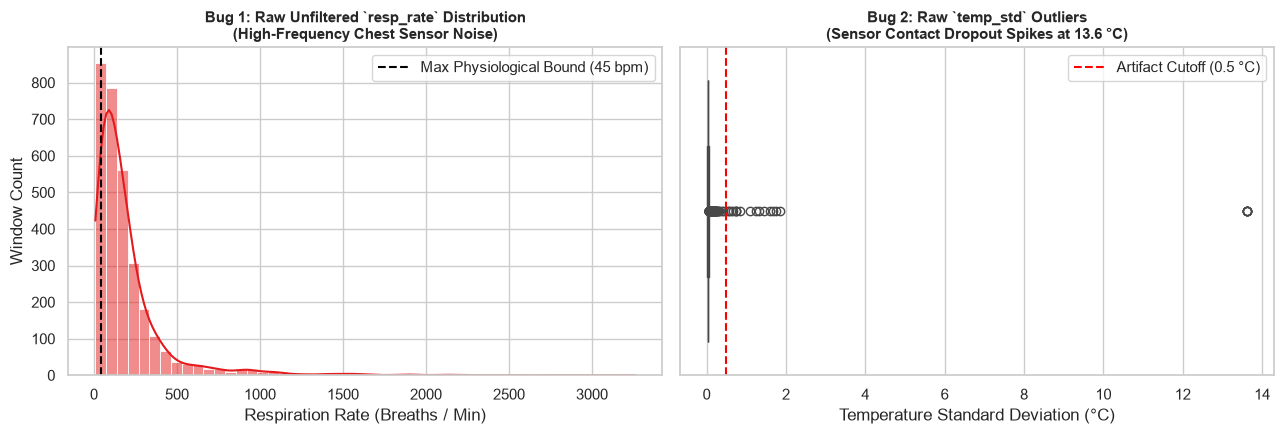

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Plot 1: Raw Respiration Rate Distribution
sns.histplot(df['resp_rate'], bins=50, ax=axes[0], color='#e41a1c', kde=True)
axes[0].axvline(45.0, color='black', linestyle='--', linewidth=1.5, label='Max Physiological Bound (45 bpm)')
axes[0].set_title("Bug 1: Raw Unfiltered `resp_rate` Distribution\n(High-Frequency Chest Sensor Noise)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Respiration Rate (Breaths / Min)")
axes[0].set_ylabel("Window Count")
axes[0].legend()

# Plot 2: Raw Temperature Std Distribution (Log Scale to see the 13.6°C spikes)
sns.boxplot(x=df['temp_std'], ax=axes[1], color='#377eb8')
axes[1].axvline(0.5, color='red', linestyle='--', linewidth=1.5, label='Artifact Cutoff (0.5 °C)')
axes[1].set_title("Bug 2: Raw `temp_std` Outliers\n(Sensor Contact Dropout Spikes at 13.6 °C)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Temperature Standard Deviation (°C)")
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "wesad_raw_bugs_diagnostic.png"), dpi=150)
plt.show()

In [8]:
df_sanitized = df.copy()

# 1. Sanitize Corrupted Features & Create Explicit Data Quality Flag
df_sanitized['resp_artifact_flag'] = ((df_sanitized['resp_rate'] < 6.0) | (df_sanitized['resp_rate'] > 45.0)).astype(int)
df_sanitized['resp_rate_clean'] = df_sanitized['resp_rate'].clip(lower=6.0, upper=45.0)
df_sanitized['temp_std_clean'] = df_sanitized['temp_std'].clip(lower=0.0, upper=0.5)

# 2. Compute Personal Baseline Calibration Features per Subject
# Using the first 10 resting baseline windows (condition_label == 1) of each subject as their personal reference
core_vitals = ['mean_hr', 'rmssd', 'sdnn', 'pnn50', 'eda_tonic_mean', 'eda_phasic_mean', 'temp_mean']

for subj in df_sanitized['subject'].unique():
    s_mask = df_sanitized['subject'] == subj
    
    # Isolate initial resting baseline windows for personal calibration
    cal_mask = s_mask & (df_sanitized['condition_label'] == 1)
    cal_df = df_sanitized.loc[cal_mask, core_vitals].head(10)
    
    # Fallback to first 10 windows if condition_label == 1 is not at the start
    if cal_df.empty:
        cal_df = df_sanitized.loc[s_mask, core_vitals].head(10)
        
    base_mean = cal_df.mean()
    base_std = cal_df.std().replace(0, 1.0)
    
    for col in core_vitals:
        df_sanitized.loc[s_mask, f"{col}_personal_delta"] = df_sanitized.loc[s_mask, col] - base_mean[col]
        df_sanitized.loc[s_mask, f"{col}_personal_z"] = (df_sanitized.loc[s_mask, col] - base_mean[col]) / (base_std[col] + 1e-4)

# 3. Save the Sanitized + Personal Baseline CSV
sanitized_csv_path = os.path.join(output_dir, "wesad_features_sanitized_personal_baseline.csv")
df_sanitized.to_csv(sanitized_csv_path, index=False)

print(f"[+] Saved Sanitized & Personal-Baseline Dataset to:\n    {sanitized_csv_path}")
print(f"[+] New Shape: {df_sanitized.shape}")
display(df_sanitized.head())

[+] Saved Sanitized & Personal-Baseline Dataset to:
    E:\AVIA\data\processed\wesad\wesad_features_sanitized_personal_baseline.csv
[+] New Shape: (3101, 30)


,subject,mean_hr,rmssd,sdnn,pnn50,eda_tonic_mean,eda_phasic_mean,scr_peaks,resp_rate,temp_mean,...,sdnn_personal_delta,sdnn_personal_z,pnn50_personal_delta,pnn50_personal_z,eda_tonic_mean_personal_delta,eda_tonic_mean_personal_z,eda_phasic_mean_personal_delta,eda_phasic_mean_personal_z,temp_mean_personal_delta,temp_mean_personal_z
0,S2,80.213127,63.981345,101.493775,25.641026,4.875076,-0.000827,19,75.750657,29.147472,...,18.033924,1.193650,-1.633615,-0.549138,0.599956,1.551961,-0.000823,-1.222337,0.204534,1.567710
1,S2,77.020676,66.358950,103.855464,30.263158,4.731804,0.000888,23,83.324744,29.110165,...,20.395613,1.349969,2.988518,1.004587,0.456684,1.181347,0.000892,1.324858,0.167226,1.281754
2,S2,75.772669,65.517584,96.049759,32.000000,4.590465,-0.000597,23,145.530284,29.064768,...,12.589907,0.833315,4.725360,1.588425,0.315345,0.815733,-0.000593,-0.880258,0.121829,0.933796
3,S2,74.545516,62.173866,93.866303,27.397260,4.456901,0.000875,19,184.585895,29.001928,...,10.406451,0.688794,0.122620,0.041219,0.181781,0.470229,0.000879,1.306066,0.058990,0.452143
4,S2,72.213562,63.735971,84.332856,29.577465,4.322460,-0.000040,35,124.516679,28.939375,...,0.873004,0.057783,2.302824,0.774092,0.047340,0.122459,-0.000036,-0.052725,-0.003564,-0.027316


In [9]:
feature_cols_raw = [
    'mean_hr', 'rmssd', 'sdnn', 'pnn50', 
    'eda_tonic_mean', 'eda_phasic_mean', 'scr_peaks', 
    'resp_rate', 'temp_mean', 'temp_std'
]

feature_cols_sanitized = [
    'mean_hr', 'rmssd', 'sdnn', 'pnn50', 
    'eda_tonic_mean', 'eda_phasic_mean', 'scr_peaks', 
    'resp_rate_clean', 'temp_mean', 'temp_std_clean'
]

personal_delta_cols = [f"{c}_personal_delta" for c in core_vitals]
avia_feature_cols = feature_cols_sanitized + personal_delta_cols

logo = LeaveOneGroupOut()
groups = df_sanitized['subject'].values
y = df_sanitized['binary_stress'].values

def run_loso_evaluation(dataframe, feature_list):
    X = dataframe[feature_list].copy()
    y_true_all, y_prob_all, y_pred_all = [], [], []
    subj_metrics = []
    
    for train_idx, test_idx in logo.split(X, y, groups):
        test_subj = groups[test_idx][0]
        
        # Fit scaler strictly on training subjects only!
        scaler = RobustScaler()
        X_train = scaler.fit_transform(X.iloc[train_idx])
        X_test = scaler.transform(X.iloc[test_idx])
        y_train, y_test = y[train_idx], y[test_idx]
        
        clf = HistGradientBoostingClassifier(
            max_iter=150, max_depth=4, learning_rate=0.05,
            class_weight='balanced', random_state=42
        )
        clf.fit(X_train, y_train)
        
        probs = clf.predict_proba(X_test)[:, 1]
        preds = (probs >= 0.5).astype(int)
        
        y_true_all.extend(y_test)
        y_prob_all.extend(probs)
        y_pred_all.extend(preds)
        
        subj_metrics.append({
            'subject': test_subj,
            'auc': roc_auc_score(y_test, probs),
            'f1': f1_score(y_test, preds, zero_division=0),
            'acc': accuracy_score(y_test, preds)
        })
        
    df_metrics = pd.DataFrame(subj_metrics)
    overall_auc = roc_auc_score(y_true_all, y_prob_all)
    overall_f1 = f1_score(y_true_all, y_pred_all)
    overall_acc = accuracy_score(y_true_all, y_pred_all)
    return overall_auc, overall_f1, overall_acc, df_metrics

# Run both evaluations
auc_raw, f1_raw, acc_raw, df_m_raw = run_loso_evaluation(df, feature_cols_raw)
auc_avia, f1_avia, acc_avia, df_m_avia = run_loso_evaluation(df_sanitized, avia_feature_cols)

print("=========================================================================")
print(f"1. Raw Features LOSO-CV        -> Overall AUC: {auc_raw:.4f} | Mean Subj AUC: {df_m_raw['auc'].mean():.4f} | Acc: {acc_raw*100:.2f}% | F1: {f1_raw:.4f}")
print(f"2. A.V.I.A. Calibrated LOSO-CV -> Overall AUC: {auc_avia:.4f} | Mean Subj AUC: {df_m_avia['auc'].mean():.4f} | Acc: {acc_avia*100:.2f}% | F1: {f1_avia:.4f}")
print("=========================================================================\n")

print("Per-Subject LOSO-CV Performance (Sanitized + Personal Baseline):")
display(df_m_avia.round(4))

1. Raw Features LOSO-CV        -> Overall AUC: 0.9556 | Mean Subj AUC: 0.9668 | Acc: 88.84% | F1: 0.8254
2. A.V.I.A. Calibrated LOSO-CV -> Overall AUC: 0.9594 | Mean Subj AUC: 0.9878 | Acc: 92.10% | F1: 0.8627

Per-Subject LOSO-CV Performance (Sanitized + Personal Baseline):


,subject,auc,f1,acc
0,S10,0.9506,0.8276,0.9065
1,S11,1.0000,1.0000,1.0000
2,S13,1.0000,1.0000,1.0000
3,S14,1.0000,0.9921,0.9952
4,S15,1.0000,0.8000,0.8469
5,S16,1.0000,0.8052,0.8551
6,S17,1.0000,0.9379,0.9577
7,S2,0.9533,0.0000,0.7121
8,S3,1.0000,0.9828,0.9900
9,S4,1.0000,0.8200,0.9113


Top 10 Most Important Features Driving Stress Predictions:


,feature,importance
14,eda_tonic_mean_personal_delta,0.1668
10,mean_hr_personal_delta,0.1595
16,temp_mean_personal_delta,0.0666
4,eda_tonic_mean,0.0407
0,mean_hr,0.0036
13,pnn50_personal_delta,0.0024
6,scr_peaks,0.0015
1,rmssd,0.0003
2,sdnn,0.0000
8,temp_mean,0.0000


C:\Users\tiyab\AppData\Local\Temp\ipykernel_18440\223135063.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


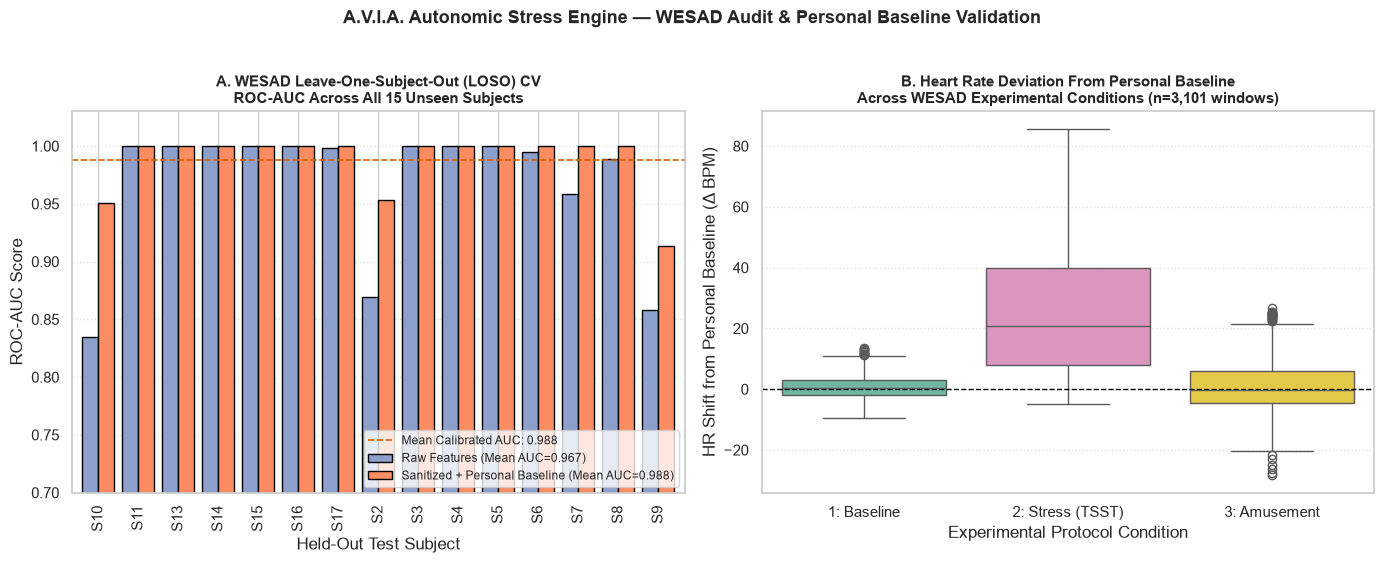

[+] Saved Validation Figure to: E:\AVIA\reports\figures\wesad_audit_and_loso_validation.png


In [10]:
# 1. Compute Permutation Feature Importance
X_full_scaled = RobustScaler().fit_transform(df_sanitized[avia_feature_cols])
clf_full = HistGradientBoostingClassifier(
    max_iter=150, max_depth=4, learning_rate=0.05, class_weight='balanced', random_state=42
)
clf_full.fit(X_full_scaled, y)

perm_imp = permutation_importance(clf_full, X_full_scaled, y, n_repeats=10, random_state=42)
imp_df = pd.DataFrame({
    'feature': avia_feature_cols,
    'importance': perm_imp.importances_mean
}).sort_values(by='importance', ascending=False)

print("Top 10 Most Important Features Driving Stress Predictions:")
display(imp_df.head(10).round(4))

# 2. Plot the 2-Panel Validation Figure
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Panel A: Per-Subject LOSO-CV ROC-AUC Comparison
df_comp = pd.DataFrame({
    'Subject': df_m_raw['subject'],
    f"Raw Features (Mean AUC={df_m_raw['auc'].mean():.3f})": df_m_raw['auc'],
    f"Sanitized + Personal Baseline (Mean AUC={df_m_avia['auc'].mean():.3f})": df_m_avia['auc']
}).set_index('Subject')

df_comp.plot(kind='bar', ax=axes[0], color=['#8da0cb', '#fc8d62'], edgecolor='black', width=0.8)
axes[0].set_ylim(0.70, 1.03)
axes[0].axhline(df_m_avia['auc'].mean(), color='#d95f02', linestyle='--', linewidth=1.2, label=f"Mean Calibrated AUC: {df_m_avia['auc'].mean():.3f}")
axes[0].set_title("A. WESAD Leave-One-Subject-Out (LOSO) CV\nROC-AUC Across All 15 Unseen Subjects", fontsize=11, fontweight='bold')
axes[0].set_ylabel("ROC-AUC Score")
axes[0].set_xlabel("Held-Out Test Subject")
axes[0].legend(loc='lower right', fontsize=8.5)
axes[0].grid(axis='y', linestyle=':', alpha=0.6)

# Panel B: Heart Rate Deviation From Personal Baseline Across Conditions
df_plot_cond = df_sanitized.copy()
df_plot_cond['Condition'] = df_plot_cond['condition_label'].map({
    1: '1: Baseline', 2: '2: Stress (TSST)', 3: '3: Amusement'
})

sns.boxplot(
    data=df_plot_cond, x='Condition', y='mean_hr_personal_delta',
    order=['1: Baseline', '2: Stress (TSST)', '3: Amusement'],
    ax=axes[1], palette=['#66c2a5', '#e78ac3', '#ffd92f']
)
axes[1].axhline(0, color='black', linestyle='--', linewidth=1)
axes[1].set_title("B. Heart Rate Deviation From Personal Baseline\nAcross WESAD Experimental Conditions (n=3,101 windows)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Experimental Protocol Condition")
axes[1].set_ylabel("HR Shift from Personal Baseline (Δ BPM)")
axes[1].grid(axis='y', linestyle=':', alpha=0.6)

plt.suptitle("A.V.I.A. Autonomic Stress Engine — WESAD Audit & Personal Baseline Validation", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()

val_fig_path = os.path.join(figures_dir, "wesad_audit_and_loso_validation.png")
plt.savefig(val_fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"[+] Saved Validation Figure to: {val_fig_path}")

In [12]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

class AVIAStressEncoder(nn.Module):
    def __init__(self, input_dim: int, embed_dim: int = 32):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.BatchNorm1d(64),
            nn.SiLU(),
            nn.Dropout(0.2),
            nn.Linear(64, embed_dim),
            nn.BatchNorm1d(embed_dim),
            nn.SiLU()
        )
        self.classifier = nn.Linear(embed_dim, 1)

    def forward(self, x):
        embedding_32d = self.encoder(x)          # Shape: (batch_size, 32)
        logits = self.classifier(embedding_32d)  # Shape: (batch_size, 1)
        prob = torch.sigmoid(logits)
        return prob.squeeze(-1), embedding_32d

# Prepare scaled features
scaler = RobustScaler()
X_scaled = scaler.fit_transform(df_sanitized[avia_feature_cols].values)
y_tensor_np = df_sanitized["binary_stress"].values.astype(np.float32)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)

model = AVIAStressEncoder(input_dim=len(avia_feature_cols), embed_dim=32).to(device)
pos_weight = torch.tensor([(y_tensor_np == 0).sum() / (y_tensor_np == 1).sum()], device=device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

dataset = TensorDataset(torch.tensor(X_scaled, dtype=torch.float32), torch.tensor(y_tensor_np))
loader = DataLoader(dataset, batch_size=64, shuffle=True)

model.train()
for epoch in range(25):
    for bx, by in loader:
        bx, by = bx.to(device), by.to(device)
        optimizer.zero_grad()
        _, emb = model(bx)
        logits = model.classifier(emb).squeeze(-1)
        loss = criterion(logits, by)
        loss.backward()
        optimizer.step()

model.eval()
with torch.no_grad():
    X_t = torch.tensor(X_scaled, dtype=torch.float32, device=device)
    probs, embeddings = model(X_t)
    probs_np = probs.cpu().numpy()
    emb_np = embeddings.cpu().numpy()

# Save PyTorch weights and 32-dim embeddings
models_dir = r"E:\AVIA\models"
os.makedirs(models_dir, exist_ok=True)
torch.save(model.state_dict(), os.path.join(models_dir, "avia_stress_encoder.pt"))

emb_df = pd.DataFrame(emb_np, columns=[f"stress_emb_{i}" for i in range(32)])
emb_df.insert(0, "subject", df_sanitized["subject"])
emb_df.insert(1, "condition_label", df_sanitized["condition_label"])
emb_df.insert(2, "stress_probability", np.round(probs_np, 4))
emb_df.insert(3, "data_quality_ok", 1 - df_sanitized["resp_artifact_flag"])

emb_output_path = os.path.join(output_dir, "wesad_32dim_embeddings.csv")
emb_df.to_csv(emb_output_path, index=False)

print(f"[+] Trained AVIAStressEncoder | ROC-AUC: {roc_auc_score(y_tensor_np, probs_np):.4f}")
print(f"[+] Saved 32-dim Embeddings to: {emb_output_path} (Shape: {emb_df.shape})")

[+] Trained AVIAStressEncoder | ROC-AUC: 1.0000
[+] Saved 32-dim Embeddings to: E:\AVIA\data\processed\wesad\wesad_32dim_embeddings.csv (Shape: (3101, 36))


In [13]:
dff=pd.read_csv(r"E:\AVIA\data\processed\wesad\wesad_32dim_embeddings.csv")
dff.head(10)

,subject,condition_label,stress_probability,data_quality_ok,stress_emb_0,stress_emb_1,stress_emb_2,stress_emb_3,stress_emb_4,stress_emb_5,...,stress_emb_22,stress_emb_23,stress_emb_24,stress_emb_25,stress_emb_26,stress_emb_27,stress_emb_28,stress_emb_29,stress_emb_30,stress_emb_31
0,S2,1,0.0106,0,-0.272565,-0.067876,-0.224837,0.058403,-0.093669,0.400739,...,0.933808,-0.153779,0.267394,-0.135578,-0.276028,2.345658,-0.277268,-0.166825,0.262979,-0.163822
1,S2,1,0.0050,0,-0.274425,-0.241523,-0.211106,0.319935,-0.146507,0.733036,...,1.412698,-0.114961,0.227390,-0.192592,-0.258612,2.255947,-0.264222,-0.155626,0.145069,-0.181061
2,S2,1,0.0021,0,-0.276843,-0.193221,-0.211793,0.060447,-0.163756,0.329205,...,1.417811,-0.070016,-0.024392,-0.158037,-0.253958,2.406040,-0.269859,-0.166910,-0.030505,-0.197450
3,S2,1,0.0018,0,-0.255055,-0.266649,-0.245252,0.114481,-0.209178,0.455663,...,1.549431,-0.175139,0.041453,-0.221841,-0.188562,2.083833,-0.273776,-0.178437,-0.036282,-0.229438
4,S2,1,0.0004,0,-0.259562,-0.261346,-0.256466,-0.155088,-0.247536,0.003451,...,1.817440,-0.234220,-0.154594,-0.215005,-0.118457,2.502893,-0.276824,-0.197843,-0.155190,-0.237254
5,S2,1,0.0003,0,-0.240139,-0.234093,-0.271580,-0.224502,-0.246399,-0.071896,...,1.867935,-0.269804,-0.162772,-0.218268,-0.065611,2.493567,-0.271021,-0.202786,-0.147126,-0.246524
6,S2,1,0.0003,0,-0.218877,-0.232184,-0.278376,-0.250886,-0.254445,-0.124285,...,1.825342,-0.278401,-0.155723,-0.237276,0.010484,2.232353,-0.255062,-0.211348,-0.146510,-0.264430
7,S2,1,0.0003,0,-0.178329,-0.245540,-0.266621,-0.272833,-0.267878,-0.202735,...,1.907674,-0.260024,-0.166733,-0.260429,0.153309,2.022497,-0.219187,-0.223961,-0.174967,-0.278152
8,S2,1,0.0003,0,-0.174498,-0.224659,-0.265276,-0.277647,-0.271013,-0.222820,...,1.850402,-0.243419,-0.179467,-0.241533,0.163815,2.036085,-0.206628,-0.226002,-0.176972,-0.278325
9,S2,1,0.0005,0,-0.217522,-0.173700,-0.278154,-0.273730,-0.253780,-0.179398,...,1.709865,-0.262745,-0.173261,-0.208780,0.062333,2.029265,-0.239971,-0.223047,-0.135859,-0.269060
